In [ ]:
# ===== Case Study 공통 Cell: histogram 겹침 구간 + 저엔트로피 오답 =====
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def load_jsonl(path):
    with open(path, encoding="utf-8") as f:
        return [
            json.loads(line)
            for line in f
        ]


def get_bin_index(value, bins):
    bin_index = np.searchsorted(
        bins,
        value,
        side="right",
    ) - 1

    return int(
        np.clip(
            bin_index,
            0,
            len(bins) - 2,
        )
    )


def merge_overlap_bins(
    overlap_indices,
    bins,
):
    """연속된 overlap bin을 하나의 entropy 구간으로 합친다."""
    if len(overlap_indices) == 0:
        return []

    ranges = []

    start = overlap_indices[0]
    previous = overlap_indices[0]

    for current in overlap_indices[1:]:
        if current == previous + 1:
            previous = current
            continue

        ranges.append(
            (
                float(bins[start]),
                float(bins[previous + 1]),
            )
        )

        start = current
        previous = current

    ranges.append(
        (
            float(bins[start]),
            float(bins[previous + 1]),
        )
    )

    return ranges


def run_overlap_case_study(
    scored_path,
    correct_key,
    output_prefix,
    display_fields,
    n_cases=10,
    min_cases=5,
    exclude_abstain=True,
):
    # scored 결과 로드
    rows = load_jsonl(scored_path)

    assert len(rows) > 0, "scored 결과가 비어 있습니다."

    assert all(
        "mean_entropy" in row
        for row in rows
    ), "mean_entropy 필드가 없습니다."

    assert all(
        correct_key in row
        for row in rows
    ), f"{correct_key} 필드가 없습니다."

    # 직접적인 정답/오답 비교를 위해 abstain 제외
    if exclude_abstain:
        analysis_rows = [
            row
            for row in rows
            if not row.get(
                "is_abstain",
                False,
            )
        ]
    else:
        analysis_rows = rows

    correct_rows = [
        row
        for row in analysis_rows
        if row[correct_key]
    ]

    wrong_rows = [
        row
        for row in analysis_rows
        if not row[correct_key]
    ]

    assert len(correct_rows) > 0, "정답 사례가 없습니다."
    assert len(wrong_rows) > 0, "오답 사례가 없습니다."

    correct_entropy = np.array([
        row["mean_entropy"]
        for row in correct_rows
    ])

    wrong_entropy = np.array([
        row["mean_entropy"]
        for row in wrong_rows
    ])

    # 기존 histogram 코드와 동일한 bin
    bins = np.linspace(
        0,
        max(
            row["mean_entropy"]
            for row in analysis_rows
        ) + 0.1,
        30,
    )

    correct_count, _ = np.histogram(
        correct_entropy,
        bins=bins,
    )

    wrong_count, _ = np.histogram(
        wrong_entropy,
        bins=bins,
    )

    # 정답과 오답이 모두 존재하는 bin
    overlap_indices = np.where(
        (correct_count > 0)
        & (wrong_count > 0)
    )[0].tolist()

    overlap_index_set = set(
        overlap_indices
    )

    overlap_ranges = merge_overlap_bins(
        overlap_indices,
        bins,
    )

    print(
        "\n분석 대상:",
        len(analysis_rows),
    )

    print(
        "정답:",
        len(correct_rows),
    )

    print(
        "오답:",
        len(wrong_rows),
    )

    print("\n[Histogram 겹침 구간]")

    if len(overlap_ranges) == 0:
        print("겹침 구간이 없습니다.")
        return pd.DataFrame()

    for left, right in overlap_ranges:
        print(
            f"  {left:.3f} <= "
            f"mean_entropy < {right:.3f}"
        )

    # 우선 정답 entropy 중앙값 이하를
    # 저엔트로피 영역으로 사용
    cutoff_quantile = 0.50

    low_entropy_cutoff = float(
        np.quantile(
            correct_entropy,
            cutoff_quantile,
        )
    )

    def find_candidates(cutoff):
        candidates = []

        for row in wrong_rows:
            entropy = row["mean_entropy"]

            bin_index = get_bin_index(
                entropy,
                bins,
            )

            if (
                bin_index in overlap_index_set
                and entropy <= cutoff
            ):
                candidates.append(row)

        return candidates

    candidates = find_candidates(
        low_entropy_cutoff
    )

    # 중앙값 기준으로 사례가 부족하면
    # 정답 entropy 75% 분위수까지 확장
    if len(candidates) < min_cases:
        cutoff_quantile = 0.75

        low_entropy_cutoff = float(
            np.quantile(
                correct_entropy,
                cutoff_quantile,
            )
        )

        candidates = find_candidates(
            low_entropy_cutoff
        )

    print(
        "\n저엔트로피 기준:",
        f"correct entropy q{int(cutoff_quantile * 100)}",
        f"= {low_entropy_cutoff:.3f}",
    )

    print(
        "저엔트로피 오답 후보:",
        len(candidates),
    )

    # 낮은 entropy부터 정렬
    candidates = sorted(
        candidates,
        key=lambda row: (
            row["mean_entropy"],
            str(row.get("id", "")),
        ),
    )

    # 같은 bin의 사례만 몰리지 않도록
    # 우선 각 overlap bin에서 한 건씩 선택
    selected = []
    selected_keys = set()

    for bin_index in overlap_indices:
        rows_in_bin = [
            row
            for row in candidates
            if get_bin_index(
                row["mean_entropy"],
                bins,
            ) == bin_index
        ]

        if len(rows_in_bin) == 0:
            continue

        row = rows_in_bin[0]

        row_key = (
            row.get("id"),
            row["prediction"],
        )

        if row_key not in selected_keys:
            selected.append(row)
            selected_keys.add(row_key)

        if len(selected) >= n_cases:
            break

    # 남은 자리는 entropy가 낮은 순서대로 채움
    for row in candidates:
        if len(selected) >= n_cases:
            break

        row_key = (
            row.get("id"),
            row["prediction"],
        )

        if row_key in selected_keys:
            continue

        selected.append(row)
        selected_keys.add(row_key)

    case_records = []

    for rank, row in enumerate(
        selected,
        start=1,
    ):
        bin_index = get_bin_index(
            row["mean_entropy"],
            bins,
        )

        # 이 오답보다 entropy가 작은 정답의 비율
        correct_percentile = float(
            np.mean(
                correct_entropy
                <= row["mean_entropy"]
            )
        )

        record = {
            "rank": rank,
            "mean_entropy": row["mean_entropy"],
            "entropy_bin_left": float(
                bins[bin_index]
            ),
            "entropy_bin_right": float(
                bins[bin_index + 1]
            ),
            "correct_entropy_percentile": (
                correct_percentile
            ),
            "is_abstain": row.get(
                "is_abstain",
                False,
            ),
        }

        for field in display_fields:
            record[field] = row.get(field)

        # 사람이 직접 분류할 열
        record["manual_type"] = ""
        record["manual_note"] = ""

        case_records.append(record)

    # JSONL 저장
    jsonl_out = (
        f"{output_prefix}_cases.jsonl"
    )

    with open(
        jsonl_out,
        "w",
        encoding="utf-8",
    ) as f:
        for record in case_records:
            f.write(
                json.dumps(
                    record,
                    ensure_ascii=False,
                ) + "\n"
            )

    # CSV 저장
    csv_records = []

    for record in case_records:
        csv_record = {}

        for key, value in record.items():
            if isinstance(
                value,
                (list, dict),
            ):
                value = json.dumps(
                    value,
                    ensure_ascii=False,
                )

            csv_record[key] = value

        csv_records.append(csv_record)

    case_df = pd.DataFrame(
        csv_records
    )

    csv_out = (
        f"{output_prefix}_cases.csv"
    )

    case_df.to_csv(
        csv_out,
        index=False,
        encoding="utf-8-sig",
    )

    # overlap 구간 표시 histogram
    plt.figure(figsize=(7, 4))

    plt.hist(
        correct_entropy,
        bins=bins,
        alpha=0.6,
        label=f"correct (n={len(correct_rows)})",
    )

    plt.hist(
        wrong_entropy,
        bins=bins,
        alpha=0.6,
        label=f"wrong (n={len(wrong_rows)})",
    )

    for left, right in overlap_ranges:
        plt.axvspan(
            left,
            right,
            alpha=0.10,
        )

    plt.axvline(
        low_entropy_cutoff,
        linestyle="--",
        label=(
            "low-entropy cutoff "
            f"({low_entropy_cutoff:.3f})"
        ),
    )

    plt.xlabel(
        "mean output entropy "
        "(nats, closed-book)"
    )

    plt.ylabel("# cases")
    plt.legend()
    plt.tight_layout()

    figure_out = (
        f"{output_prefix}_overlap_hist.png"
    )

    plt.savefig(
        figure_out,
        dpi=150,
    )

    plt.show()

    print("\n저장 완료:")
    print(" ", jsonl_out)
    print(" ", csv_out)
    print(" ", figure_out)

    if len(case_records) < min_cases:
        print(
            "\n주의: 조건을 만족하는 사례가",
            f"{len(case_records)}건뿐입니다.",
        )

    return case_df

In [ ]:
# ===== Exp6-Qwen Case Study =====
exp6_qwen_case_df = run_overlap_case_study(
    scored_path="exp6_qwen_scored.jsonl",
    correct_key="is_correct",
    output_prefix="case_study_exp6_qwen",
    display_fields=[
        "id",
        "question",
        "gold",
        "aliases",
        "prediction",
        "source",
        "matched",
        "mean_logprob",
        "n_tokens",
    ],
    n_cases=10,
    min_cases=5,
    exclude_abstain=True,
)

exp6_qwen_case_df


분석 대상: 398
정답: 77
오답: 321

[Histogram 겹침 구간]
  0.000 <= mean_entropy < 0.574
  0.637 <= mean_entropy < 0.765
  0.892 <= mean_entropy < 1.020

저엔트로피 기준: correct entropy q50 = 0.174
저엔트로피 오답 후보: 29


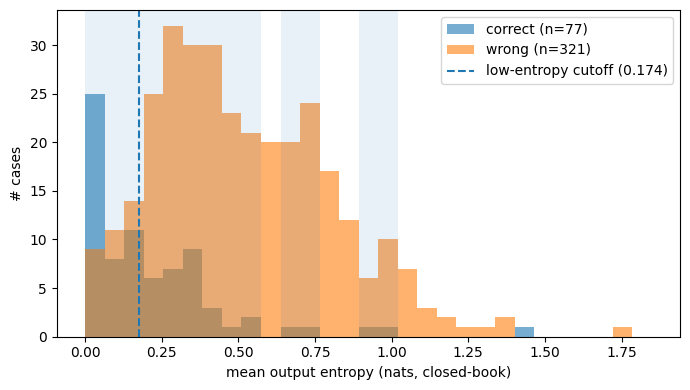


저장 완료:
  case_study_exp7_qwen_cases.jsonl
  case_study_exp7_qwen_cases.csv
  case_study_exp7_qwen_overlap_hist.png


,rank,mean_entropy,entropy_bin_left,entropy_bin_right,correct_entropy_percentile,is_abstain,id,question,obj,replace_name,prediction,match_outcome,num_edits,s_pop,source,mean_logprob,n_tokens,manual_type,manual_note
0,1,0.000302,0.000000,0.063736,0.025974,False,dqa_384,What is London the capital of?,Great Britain,United Kingdom of Great Britain and Ireland,London is the capital of the United Kingdom.,neither,12.0,523018,copenlu/dynamicqa temporal test seed42,-0.000029,10,,
1,2,0.080609,0.063736,0.127472,0.324675,False,dqa_389,What genre is Portia White?,opera,symphony,Portia White was a classical singer.,neither,2.0,796,copenlu/dynamicqa temporal test seed42,-0.018137,9,,
2,3,0.130060,0.127472,0.191209,0.454545,False,dqa_190,What is Henry Campbell-Bannerman's occupation?,diplomat,statesperson,Henry Campbell-Bannerman was a British politic...,neither,2.0,8010,copenlu/dynamicqa temporal test seed42,-0.046995,41,,
3,4,0.000779,0.000000,0.063736,0.051948,False,dqa_109,What is the capital of Confederate States of A...,Montgomery,Harrisburg,The capital of the Confederate States of Ameri...,neither,3.0,125923,copenlu/dynamicqa temporal test seed42,-0.000084,14,,
4,5,0.005589,0.000000,0.063736,0.129870,False,dqa_002,What is City of Brussels the capital of?,Brussels Capital Region,Anderlecht,City of Brussels is the capital of Belgium.,neither,12.0,26794,copenlu/dynamicqa temporal test seed42,-0.000781,10,,
5,6,0.013807,0.000000,0.063736,0.220779,False,dqa_256,What is Beijing the capital of?,Taiwan,Lebanon,Beijing is the capital of the People's Republi...,neither,7.0,125585,copenlu/dynamicqa temporal test seed42,-0.003485,14,,
6,7,0.018971,0.000000,0.063736,0.233766,False,dqa_300,Who was the screenwriter for Pulp Fiction?,Roger Avary,Thom Fitzgerald,The screenwriter for Pulp Fiction was Quentin ...,neither,2.0,164826,copenlu/dynamicqa temporal test seed42,-0.003437,13,,
7,8,0.023108,0.000000,0.063736,0.233766,False,dqa_364,What is Famke Janssen's occupation?,actor,film actor,Famke Janssen is an actress.,neither,6.0,126052,copenlu/dynamicqa temporal test seed42,-0.004073,11,,
8,9,0.029872,0.000000,0.063736,0.272727,False,dqa_133,What genre is Ordeal in Space?,short story,essay,Ordeal in Space is a science fiction novel.,neither,2.0,183,copenlu/dynamicqa temporal test seed42,-0.004648,11,,
9,10,0.035024,0.000000,0.063736,0.272727,False,dqa_359,What is Atlanta the capital of?,Fulton County,Cobb County,Atlanta is the capital of Georgia.,neither,2.0,155804,copenlu/dynamicqa temporal test seed42,-0.008165,8,,


In [ ]:
# ===== Exp7-Qwen Case Study =====
exp7_qwen_case_df = run_overlap_case_study(
    scored_path="exp7_qwen_scored.jsonl",
    correct_key="matches_any",
    output_prefix="case_study_exp7_qwen",
    display_fields=[
        "id",
        "question",
        "obj",
        "replace_name",
        "prediction",
        "match_outcome",
        "num_edits",
        "s_pop",
        "source",
        "mean_logprob",
        "n_tokens",
    ],
    n_cases=10,
    min_cases=5,
    exclude_abstain=True,
)

exp7_qwen_case_df

In [ ]:
# ===== Exp7-Qwen Case Study: num_edits 분포 =====
if len(exp7_qwen_case_df) > 0:
    print(
        exp7_qwen_case_df[
            "num_edits"
        ].value_counts(
            sort=False
        ).sort_index()
    )

    print("\n[구간별 사례 수]")

    for lo, hi, label in [
        (2, 2, "edits=2"),
        (3, 4, "edits=3-4"),
        (5, 99, "edits=5+"),
    ]:
        count = (
            (
                exp7_qwen_case_df["num_edits"]
                >= lo
            )
            & (
                exp7_qwen_case_df["num_edits"]
                <= hi
            )
        ).sum()

        print(
            label,
            ":",
            int(count),
        )

num_edits
2.0     5
3.0     1
6.0     1
7.0     1
12.0    2
Name: count, dtype: int64

[구간별 사례 수]
edits=2 : 5
edits=3-4 : 1
edits=5+ : 4


In [ ]:
# ===== Exp7-Qwen: 전체 저엔트로피 오답의 num_edits 분석 =====
import numpy as np
import pandas as pd


SCORED_PATH = "exp7_qwen_scored.jsonl"


rows = load_jsonl(
    SCORED_PATH
)


analysis_rows = [
    row
    for row in rows
    if not row.get(
        "is_abstain",
        False,
    )
]


correct_rows = [
    row
    for row in analysis_rows
    if row["matches_any"]
]


correct_entropy = np.array([
    row["mean_entropy"]
    for row in correct_rows
])


bins = np.linspace(
    0,
    max(
        row["mean_entropy"]
        for row in analysis_rows
    ) + 0.1,
    30,
)


correct_count, _ = np.histogram(
    [
        row["mean_entropy"]
        for row in analysis_rows
        if row["matches_any"]
    ],
    bins=bins,
)


wrong_count, _ = np.histogram(
    [
        row["mean_entropy"]
        for row in analysis_rows
        if not row["matches_any"]
    ],
    bins=bins,
)


overlap_indices = set(
    np.where(
        (correct_count > 0)
        & (wrong_count > 0)
    )[0].tolist()
)


low_entropy_cutoff = float(
    np.quantile(
        correct_entropy,
        0.50,
    )
)


def edit_group(num_edits):
    if num_edits == 2:
        return "edits=2"

    if 3 <= num_edits <= 4:
        return "edits=3-4"

    return "edits=5+"


records = []


for row in analysis_rows:
    entropy = row["mean_entropy"]

    bin_index = get_bin_index(
        entropy,
        bins,
    )

    is_wrong = not row["matches_any"]

    is_low_entropy_wrong = (
        is_wrong
        and entropy <= low_entropy_cutoff
        and bin_index in overlap_indices
    )

    records.append({
        "id": row["id"],
        "num_edits": row["num_edits"],
        "edit_group": edit_group(
            row["num_edits"]
        ),
        "mean_entropy": entropy,
        "is_wrong": is_wrong,
        "is_low_entropy_wrong": (
            is_low_entropy_wrong
        ),
    })


edit_df = pd.DataFrame(
    records
)


edit_summary = (
    edit_df
    .groupby(
        "edit_group",
        sort=False,
    )
    .agg(
        n_total=(
            "id",
            "size",
        ),
        n_wrong=(
            "is_wrong",
            "sum",
        ),
        n_low_entropy_wrong=(
            "is_low_entropy_wrong",
            "sum",
        ),
        mean_entropy=(
            "mean_entropy",
            "mean",
        ),
    )
    .reset_index()
)


edit_summary[
    "low_entropy_wrong_rate"
] = (
    edit_summary[
        "n_low_entropy_wrong"
    ]
    / edit_summary[
        "n_total"
    ]
)


edit_summary[
    "low_entropy_rate_among_wrong"
] = (
    edit_summary[
        "n_low_entropy_wrong"
    ]
    / edit_summary[
        "n_wrong"
    ]
)


edit_summary

,edit_group,n_total,n_wrong,n_low_entropy_wrong,mean_entropy,low_entropy_wrong_rate,low_entropy_rate_among_wrong
0,edits=5+,62,42,8,0.329669,0.129032,0.190476
1,edits=3-4,125,94,3,0.469699,0.024000,0.031915
2,edits=2,211,185,18,0.493672,0.085308,0.097297
